# Fantasy Premier League 26/27 Performance EDA
This Exploratory Data Analysis (EDA) explores the cleaned player performance dataset to uncover trends, top performers, and metric distributions.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Set display options
pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid')

## 1. Load Cleaned Dataset

In [2]:
df = pd.read_csv('../../data/processed/players_cleaned.csv')
print(f"Dataset shape: {df.shape}")
df.head()

Dataset shape: (672, 19)


,first_name,second_name,team_name,position,now_cost,minutes,goals_scored,assists,clean_sheets,expected_goals,expected_assists,total_points,market_value_m,goals_per_90,assists_per_90,xg_per_90,xa_per_90,points_per_million,minutes_share
0,David,Raya Martín,Arsenal,Goalkeeper,62,900,0,0,7,0.00,0.01,60,6.2,0.0,0.0,0.000000,0.001000,9.677419,0.263158
1,Kepa,Arrizabalaga Revuelta,Arsenal,Goalkeeper,49,0,0,0,0,0.00,0.00,0,4.9,0.0,0.0,0.000000,0.000000,0.000000,0.000000
2,Illan,Meslier,Arsenal,Goalkeeper,49,0,0,0,0,0.00,0.00,0,4.9,0.0,0.0,0.000000,0.000000,0.000000,0.000000
3,Gabriel,dos Santos Magalhães,Arsenal,Defender,81,900,1,0,7,1.47,0.25,66,8.1,0.1,0.0,0.147000,0.025000,8.148148,0.263158
4,Jurriën,Timber,Arsenal,Defender,65,335,0,0,2,0.02,0.57,14,6.5,0.0,0.0,0.005373,0.153134,2.153846,0.097953


## 2. Statistical Summary

In [3]:
df.describe()

,now_cost,minutes,goals_scored,assists,clean_sheets,expected_goals,expected_assists,total_points,market_value_m,goals_per_90,assists_per_90,xg_per_90,xa_per_90,points_per_million,minutes_share
count,672.000000,672.00000,672.000000,672.000000,672.000000,672.000000,672.000000,672.000000,672.000000,672.000000,672.000000,672.000000,672.000000,672.000000,672.000000
mean,50.529762,292.63244,0.386905,0.361607,0.998512,0.438676,0.264345,13.608631,5.052976,0.137796,0.079833,0.144278,0.061187,2.539858,0.085565
std,9.809923,323.75093,0.962334,0.834367,1.599645,0.875618,0.443102,16.170850,0.980992,1.199968,0.279635,0.795663,0.180073,2.941141,0.094664
min,39.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.900000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,45.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4.500000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,49.000000,154.00000,0.000000,0.000000,0.000000,0.030000,0.040000,7.000000,4.900000,0.000000,0.000000,0.015180,0.017127,1.354895,0.045029
75%,54.000000,571.50000,0.000000,0.000000,2.000000,0.440000,0.340000,24.000000,5.400000,0.000000,0.000000,0.129163,0.084458,4.528214,0.167105
max,158.000000,900.00000,9.000000,6.000000,7.000000,7.290000,2.940000,75.000000,15.800000,30.000000,4.736842,15.300000,4.200000,13.636364,0.263158


## 3. Position-wise Performance breakdown
Let's see how total points and goal contributions differ across player positions (Forward, Midfielder, Defender, Goalkeeper).

In [4]:
position_summary = df.groupby('position')[['goals_scored', 'assists', 'total_points', 'market_value_m']].mean().reset_index()
position_summary.sort_values(by='total_points', ascending=False)

,position,goals_scored,assists,total_points,market_value_m
0,Defender,0.168950,0.255708,14.867580,4.598174
3,Midfielder,0.488294,0.501672,13.806020,5.369565
1,Forward,0.974684,0.455696,13.227848,5.672152
2,Goalkeeper,0.000000,0.013333,9.546667,4.466667


## 4. Correlation Heatmap
Let's check how metrics like market value, expected goals, and total points correlate with each other.

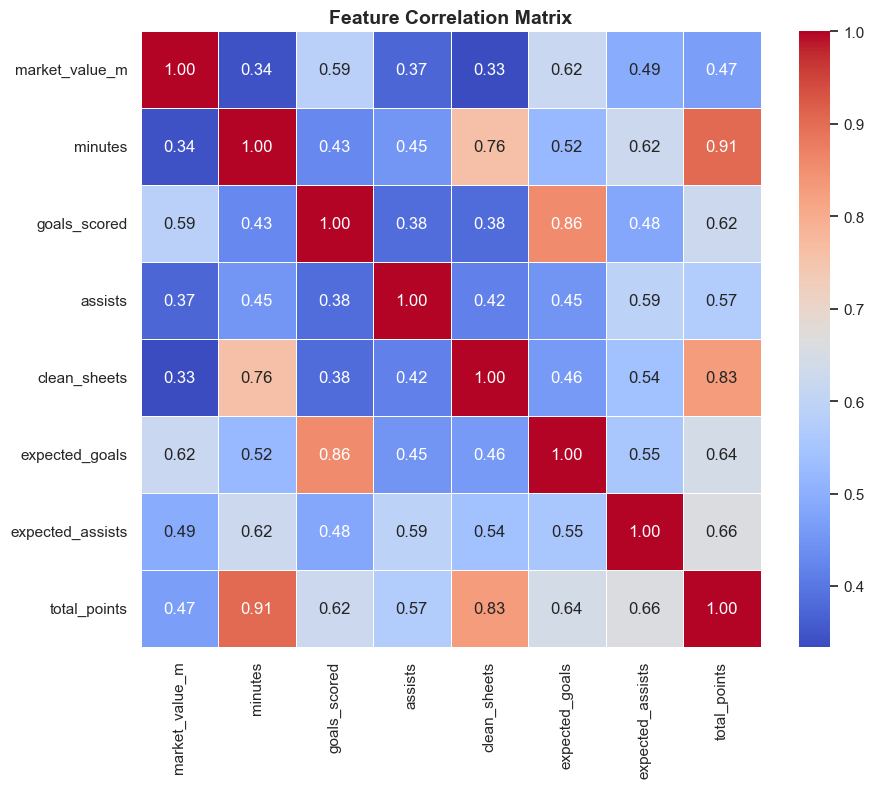

In [5]:
numeric_cols = ['market_value_m', 'minutes', 'goals_scored', 'assists', 'clean_sheets', 'expected_goals', 'expected_assists', 'total_points']
corr = df[numeric_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Feature Correlation Matrix', fontsize=14, fontweight='bold')
plt.show()